# Interactive risk map

**Hover over a tile** to see the final risk score the API would serve for it: risk (0–1 percentile),
probability, the top reasons (SHAP), and the nearest blue-light phone. The panel on the right draws
that tile's 24-hour risk curve. Use the **hour slider** to recolour the map.

Seaborn sets the theme and palettes, and matplotlib draws the hexes. Hovering needs the interactive
`ipympl` backend:

```bash
pip install seaborn ipympl ipywidgets
```

Restart Jupyter after installing. Without `ipympl` the map still draws, but it can't respond to the
mouse. Scores come from `scoring/cache/risk_cache.json`. If you pick another `DATE`, the notebook
rebuilds them with `build_cache` (about 3 s).

In [1]:
import sys, json, datetime as dt
from pathlib import Path

here = Path.cwd().resolve()
repo_root = here.parent if here.name == "algorithm" else here
sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import h3
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize
from IPython.display import display

try:
    get_ipython().run_line_magic("matplotlib", "widget")   # interactive: hover + slider
    INTERACTIVE = True
except Exception as e:
    get_ipython().run_line_magic("matplotlib", "inline")
    INTERACTIVE = False
    print("ipympl not available, so the map is static (pip install ipympl ipywidgets, then restart Jupyter).", e)

from algorithm.common import config, geo
from algorithm.scoring import score as S

sns.set_theme(style="white", context="notebook")
RISK_CMAP = sns.color_palette("rocket_r", as_cmap=True)   # light = low risk, dark red = high
NO_DATA_COLOR = sns.color_palette("Greys")[1]
print("interactive:", INTERACTIVE)


interactive: True


## 1. Load the final scores

Pick the date to show. The scores are exactly what `score_cell` / `explain_cell` return:
**risk** is the 0–1 percentile among 2023 cell-hours, and **prob** is the calibrated probability of an
incident in that cell-hour, after the blue-light factor.

In [2]:
DATE = "2026-11-14"   # any YYYY-MM-DD; dates after 2023 use history up to 2023-12-31

cache = json.loads(config.CACHE_PATH.read_text()) if config.CACHE_PATH.exists() else None
if cache is None or cache["date"] != DATE:
    print(f"building scores for {DATE} ...")
    cache = S.build_cache(DATE)
feats, labels = cache["features"], cache["feature_labels"]
CELLS = cache["cells"]
NO_DATA = set(cache["no_data_cells"])

# One row per (cell, hour): the table behind the map
scores = pd.DataFrame([
    {"cell": c, "hour": h, "risk": v["risk"][h], "prob": v["prob"][h],
     "lat": v["lat"], "lon": v["lon"], "bluelight_m": v["bluelight_dist_m"]}
    for c, v in CELLS.items() for h in range(24)])
print(f"{len(CELLS):,} modelled tiles × 24 hours for {cache['date']} "
      f"(history as of {cache['history_as_of']}); {len(NO_DATA):,} no-data tiles")
scores.head()


1,451 modelled tiles × 24 hours for 2026-11-14 (history as of 2023-12-31); 273 no-data tiles


,cell,hour,risk,prob,lat,lon,bluelight_m
0,8929a199003ffff,0,0.6320,0.00672,34.028138,-118.365328,6873
1,8929a199003ffff,1,0.5131,0.00514,34.028138,-118.365328,6873
2,8929a199003ffff,2,0.4097,0.00401,34.028138,-118.365328,6873
3,8929a199003ffff,3,0.3350,0.00331,34.028138,-118.365328,6873
4,8929a199003ffff,4,0.2821,0.00284,34.028138,-118.365328,6873


## 2. Hover map

Move the mouse over a tile. Grey tiles are inside the 5-mile circle but have no LAPD data (other
police departments): unknown, not safe. Blue dots are USC blue-light phones.

IntSlider(value=22, description='hour', max=23)

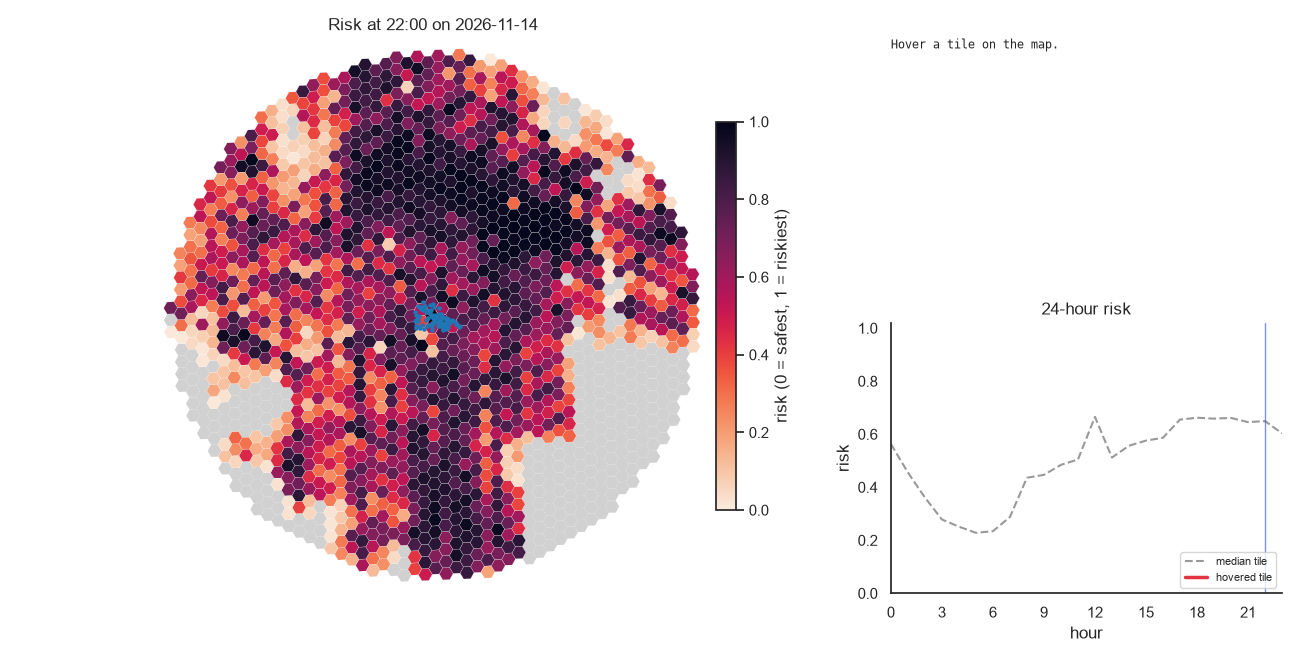

In [3]:
HOUR = 22
cell_ids = list(CELLS)
risk_by_hour = np.array([CELLS[c]["risk"] for c in cell_ids])          # (n_cells, 24)
polys = [[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in cell_ids]
phones = np.array([(a, b) for a, b, _ in geo.bluelight_phones()])

def tile_text(cell, hour):
    """What the tooltip says for one tile at one hour."""
    if cell in NO_DATA:
        return f"{cell}\nno LAPD data here (another police department)\nrisk unknown, not safe"
    v = CELLS.get(cell)
    if v is None:
        return None
    lines = [f"{cell}   {hour:02d}:00",
             f"risk  {v['risk'][hour]:.2f}   (riskier than {v['risk'][hour]:.0%} of cell-hours)",
             f"prob  {v['prob'][hour]:.2%} chance of a reported incident this hour",
             f"blue-light phone {v['bluelight_dist_m']:,} m away"]
    lines.append("why:")
    for j, effect in v["top_factors"][hour]:
        arrow = "▲" if effect > 0 else "▼"
        lines.append(f"  {arrow} {labels.get(feats[j], feats[j])} ({effect:+.2f})")
    return "\n".join(lines)

map_fig = plt.figure(figsize=(13, 6.6))
gs = map_fig.add_gridspec(2, 2, width_ratios=[2.1, 1], height_ratios=[1, 1.1])
ax = map_fig.add_subplot(gs[:, 0])          # the map
ax_info = map_fig.add_subplot(gs[0, 1])     # tile details
ax_curve = map_fig.add_subplot(gs[1, 1])    # tile's 24-hour curve
ax_info.axis("off")
info = ax_info.text(0, 1, "Hover a tile on the map.", va="top", ha="left", fontsize=8.5, family="monospace",
                    transform=ax_info.transAxes)
if INTERACTIVE:
    map_fig.canvas.header_visible = False
ax.add_collection(PolyCollection([[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in NO_DATA],
                                 facecolor=NO_DATA_COLOR, edgecolor="none"))
pc = PolyCollection(polys, array=risk_by_hour[:, HOUR], cmap=RISK_CMAP, norm=Normalize(0, 1),
                    edgecolor="white", linewidth=0.15)
ax.add_collection(pc)
ax.scatter(phones[:, 1], phones[:, 0], s=5, color=sns.color_palette("tab10")[0], zorder=3, label="blue-light phone")
s_, w_, n_, e_ = config.BBOX
pad = 0.004
ax.set_xlim(w_ - pad, e_ + pad); ax.set_ylim(s_ - pad, n_ + pad)
ax.set_aspect(1 / np.cos(np.radians(config.CENTER[0])))
ax.plot(config.CENTER[1], config.CENTER[0], marker="*", color="black", ms=11)
ax.set_xticks([]); ax.set_yticks([]); sns.despine(ax=ax, left=True, bottom=True)
title = ax.set_title(f"Risk at {HOUR:02d}:00 on {cache['date']}")
map_fig.colorbar(pc, ax=ax, shrink=0.7, pad=0.01, label="risk (0 = safest, 1 = riskiest)")

highlight = PolyCollection([], facecolor="none", edgecolor="#1d4ed8", linewidth=2, zorder=4)
ax.add_collection(highlight)
# small label next to the cursor; the full details go in the panel on the right
tip = ax.annotate("", xy=(0, 0), xytext=(10, 10), textcoords="offset points", fontsize=9, weight="bold",
                  bbox=dict(boxstyle="round", fc="white", ec="#555", alpha=0.9), zorder=5)
tip.set_visible(False)

# Right panel: the hovered tile's 24-hour curve (seaborn styling)
sns.lineplot(x=range(24), y=np.median(risk_by_hour, axis=0), ax=ax_curve, color="#999", linestyle="--",
             label="median tile")
curve, = ax_curve.plot(range(24), np.full(24, np.nan), lw=2.5, color=sns.color_palette("rocket")[3], label="hovered tile")
hour_mark = ax_curve.axvline(HOUR, color="#1d4ed8", lw=1, alpha=0.6)
ax_curve.set(xlim=(0, 23), ylim=(0, 1.02), xticks=range(0, 24, 3), xlabel="hour", ylabel="risk",
             title="24-hour risk")
ax_curve.legend(loc="lower right", fontsize=8); sns.despine(ax=ax_curve)
map_fig.tight_layout()

state = {"cell": None, "hour": HOUR}

def show(cell, lon, lat):
    """Update the label, details panel, outline and curve for one tile."""
    text = tile_text(cell, state["hour"]) if cell else None
    if text is None:
        tip.set_visible(False); highlight.set_verts([]); curve.set_ydata(np.full(24, np.nan))
        info.set_text("Hover a tile on the map.")
    else:
        v = CELLS.get(cell)
        tip.xy = (lon, lat)
        tip.set_text(f"risk {v['risk'][state['hour']]:.2f}" if v else "no data")
        # flip the label to the other side of the cursor in the right / top half of the map
        right, top = lon > (w_ + e_) / 2, lat > (s_ + n_) / 2
        tip.set_position((-10 if right else 10, -10 if top else 10))
        tip.set_ha("right" if right else "left"); tip.set_va("top" if top else "bottom")
        tip.set_visible(True)
        info.set_text(text)
        highlight.set_verts([[(x, y) for y, x in h3.cell_to_boundary(cell)]])
        curve.set_ydata(v["risk"] if v else np.full(24, np.nan))
    state["cell"] = cell
    map_fig.canvas.draw_idle()

def on_move(event):
    if event.inaxes is not ax or event.xdata is None:
        if state["cell"] is not None:
            show(None, 0, 0)
        return
    cell = h3.latlng_to_cell(event.ydata, event.xdata, config.H3_RES)
    if cell not in CELLS and cell not in NO_DATA:
        cell = None
    if cell != state["cell"]:
        show(cell, event.xdata, event.ydata)

map_fig.canvas.mpl_connect("motion_notify_event", on_move)

def set_hour(hour):
    state["hour"] = hour
    pc.set_array(risk_by_hour[:, hour])
    title.set_text(f"Risk at {hour:02d}:00 on {cache['date']}")
    hour_mark.set_xdata([hour, hour])
    if state["cell"]:
        show(state["cell"], *tip.xy)
    map_fig.canvas.draw_idle()

if INTERACTIVE:
    import ipywidgets as widgets
    slider = widgets.IntSlider(value=HOUR, min=0, max=23, description="hour", continuous_update=True)
    slider.observe(lambda ch: set_hour(ch["new"]), names="value")
    display(slider)
plt.show()


## 3. Look up a place by name or coordinates

The same tooltip text, for a specific spot, without the mouse.

In [ ]:
PLACES = {
    "Tommy Trojan (USC)": (34.0206, -118.2854),
    "USC Village": (34.0254, -118.2851),
    "Figueroa & Adams": (34.0328, -118.2747),
    "DTLA, 7th St/Metro Center": (34.0486, -118.2587),
    "Koreatown, Wilshire & Western": (34.0617, -118.3089),
    "Hancock Park": (34.0690, -118.3360),
}
for name, (lat, lng) in PLACES.items():
    print(f"--- {name}")
    print(tile_text(h3.latlng_to_cell(lat, lng, config.H3_RES), state["hour"]) or "outside the model area")


--- Tommy Trojan (USC)
8929a1d6457ffff   22:00
risk  0.53   (riskier than 53% of cell-hours)
prob  0.53% chance of a reported incident this hour
blue-light phone 28 m away
why:
  ▲ time of day (+0.21)
  ▼ long-run rate here at this hour (-0.15)
  ▲ area-wide incidents, last 7 days (+0.11)
--- USC Village
8929a1d647bffff   22:00
risk  0.72   (riskier than 72% of cell-hours)
prob  0.83% chance of a reported incident this hour
blue-light phone 70 m away
why:
  ▲ time of day (+0.17)
  ▲ long-run incident rate here (+0.14)
  ▲ area-wide incidents, last 7 days (+0.12)
--- Figueroa & Adams
8929a1d66abffff   22:00
risk  0.60   (riskier than 60% of cell-hours)
prob  0.62% chance of a reported incident this hour
blue-light phone 1,043 m away
why:
  ▲ time of day (+0.21)
  ▼ long-run rate here at this hour (-0.15)
  ▼ recent serious crime here around this time of day (-0.08)
--- DTLA, 7th St/Metro Center
8929a1d62cbffff   22:00
risk  0.99   (riskier than 99% of cell-hours)
prob  13.06% chance of 

## 4. Seaborn views of the same scores

How risk spreads across tiles by hour of day, and the riskiest tiles hour by hour.

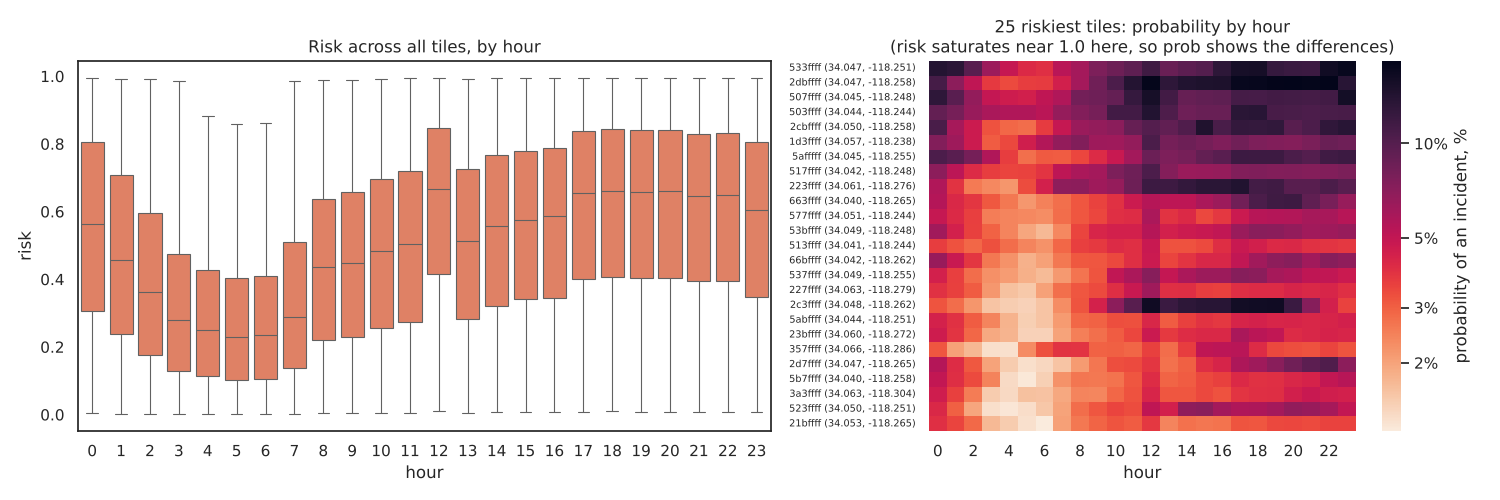

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.boxplot(data=scores, x="hour", y="risk", ax=axes[0], color=sns.color_palette("rocket")[4],
            fliersize=0, linewidth=0.8)
axes[0].set(title="Risk across all tiles, by hour", xlabel="hour", ylabel="risk")

top = (scores.groupby("cell").risk.mean().sort_values(ascending=False).head(25).index)
grid = scores[scores.cell.isin(top)].pivot(index="cell", columns="hour", values="prob").loc[top] * 100
grid.index = [f"{c[-7:]} ({CELLS[c]['lat']:.3f}, {CELLS[c]['lon']:.3f})" for c in grid.index]
from matplotlib.colors import LogNorm
hm = sns.heatmap(grid, ax=axes[1], cmap=RISK_CMAP, yticklabels=True, norm=LogNorm(grid.values.min(), grid.values.max()),
                 cbar_kws={"label": "probability of an incident, %"})
cbar = hm.collections[0].colorbar
ticks = [t for t in (1, 2, 3, 5, 10, 20, 30, 50) if grid.values.min() <= t <= grid.values.max()]
cbar.set_ticks(ticks); cbar.set_ticklabels([f"{t}%" for t in ticks]); cbar.minorticks_off()
axes[1].set(title="25 riskiest tiles: probability by hour\n(risk saturates near 1.0 here, so prob shows the differences)",
            xlabel="hour", ylabel="")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()
